<a href="https://colab.research.google.com/github/Milu2662/BI-PYMES-ML/blob/main/notebook/04_isolation_forest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BI-PYMES-ML

In [29]:
!git clone https://github.com/Milu2662/BI-PYMES-ML.git /content/BI-PYMES-ML

fatal: destination path '/content/BI-PYMES-ML' already exists and is not an empty directory.


In [30]:
from pathlib import Path
import sys
candidates=[Path("/content/BI-PYMES-ML"),Path("/content/SME-DataTrust-BI"),Path.cwd()]
PROJECT_DIR=next((p for p in candidates if (p/"src").exists()),Path.cwd())
if not (PROJECT_DIR/"src").exists():
    raise FileNotFoundError("No se encontró src/. Ajusta PROJECT_DIR a la raíz del repositorio.")
sys.path.insert(0,str(PROJECT_DIR))
for d in ["data/raw","data/processed","data/experimental","results/figures","results/metrics"]:
    (PROJECT_DIR/d).mkdir(parents=True,exist_ok=True)
print("Proyecto:",PROJECT_DIR)

Proyecto: /content/BI-PYMES-ML


In [31]:
from pathlib import Path
import shutil
import pandas as pd

source = Path(
    "/content/drive/MyDrive/BI-PYMES-ML/invoice_features.pkl"
)

destination = PROJECT_DIR / "data/processed/invoice_features.pkl"

if not source.exists():
    raise FileNotFoundError(
        "No existe invoice_features.pkl en Google Drive. "
        "Debes guardarlo primero desde Notebook 03."
    )

destination.parent.mkdir(parents=True, exist_ok=True)

shutil.copy2(source, destination)

invoice = pd.read_pickle(destination)

print("Archivo cargado")

Archivo cargado


## 4. Isolation Forest
El parámetro `contamination` representa una fracción esperada configurada para el algoritmo; no es una medición conocida de errores reales.

In [32]:
import pandas as pd, joblib
from src.anomaly_detection import fit_isolation_forest
p=PROJECT_DIR/"data/processed/invoice_features.pkl"
if not p.exists(): raise FileNotFoundError("Ejecuta primero Notebook 03.")
invoice=pd.read_pickle(p)
model,scored,features=fit_isolation_forest(invoice,contamination=.03,random_state=42)
print("Variables:",features,"\nSeñaladas:",int(scored.if_anomaly.sum()))
display(scored.sort_values("if_score",ascending=False).head(15))
scored.to_csv(PROJECT_DIR/"results/metrics/isolation_forest_scores.csv",index=False)
joblib.dump(model,PROJECT_DIR/"results/metrics/isolation_forest_pipeline.joblib")

Variables: ['line_count', 'total_quantity', 'mean_quantity', 'mean_unit_price', 'total_revenue', 'revenue_abs', 'min_unit_price', 'max_unit_price', 'cancellation_line_share'] 
Señaladas: 1609


,InvoiceNo,line_count,total_quantity,mean_quantity,mean_unit_price,total_revenue,revenue_abs,min_unit_price,max_unit_price,cancellation_line_share,invoice_date,customer_id,country,invoice_month,if_label,if_anomaly,if_score
49866,C537644,2,-2,-1.0,13474.79,-26949.58,26949.58,13474.79,13474.79,1.0,2010-12-07 15:34:00,NaN,United Kingdom,2010-12,-1,1,0.251395
49865,C537630,2,-2,-1.0,13541.33,-27082.66,27082.66,13541.33,13541.33,1.0,2010-12-07 15:04:00,NaN,United Kingdom,2010-12,-1,1,0.251395
49868,C537651,2,-2,-1.0,13541.33,-27082.66,27082.66,13541.33,13541.33,1.0,2010-12-07 15:49:00,NaN,United Kingdom,2010-12,-1,1,0.251395
51582,C556445,1,-1,-1.0,38970.00,-38970.00,38970.00,38970.00,38970.00,1.0,2011-06-10 15:31:00,15098.0,United Kingdom,2011-06,-1,1,0.251209
47612,C512770,1,-1,-1.0,25111.09,-25111.09,25111.09,25111.09,25111.09,1.0,2010-06-17 16:52:00,17399.0,United Kingdom,2010-06,-1,1,0.250464
48356,C520667,1,-1,-1.0,18910.69,-18910.69,18910.69,18910.69,18910.69,1.0,2010-08-27 13:42:00,NaN,United Kingdom,2010-08,-1,1,0.250092
53545,C580605,1,-1,-1.0,17836.46,-17836.46,17836.46,17836.46,17836.46,1.0,2011-12-05 11:36:00,NaN,United Kingdom,2011-12,-1,1,0.250092
50125,C540117,1,-1,-1.0,16888.02,-16888.02,16888.02,16888.02,16888.02,1.0,2011-01-05 09:55:00,NaN,United Kingdom,2011-01,-1,1,0.249906
50126,C540118,1,-1,-1.0,16453.71,-16453.71,16453.71,16453.71,16453.71,1.0,2011-01-05 09:57:00,NaN,United Kingdom,2011-01,-1,1,0.249906
48531,C522793,1,-1,-1.0,10468.80,-10468.80,10468.80,10468.80,10468.80,1.0,2010-09-16 14:53:00,14063.0,United Kingdom,2010-09,-1,1,0.248606


['/content/BI-PYMES-ML/results/metrics/isolation_forest_pipeline.joblib']

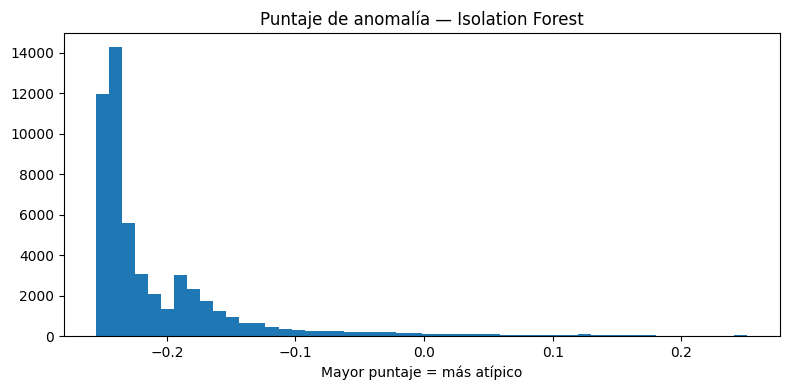

In [33]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,4)); plt.hist(scored.if_score,bins=50)
plt.title("Puntaje de anomalía — Isolation Forest")
plt.xlabel("Mayor puntaje = más atípico"); plt.tight_layout()
plt.savefig(PROJECT_DIR/"results/figures/isolation_forest_scores.png",dpi=160); plt.show()

In [34]:
import pandas as pd
import numpy as np

# AUDITORÍA DE RESULTADOS ISOLATION FOREST

results = scored.copy()

# Identificar facturas de cancelación
results["is_cancellation_invoice"] = (
    results["InvoiceNo"]
    .astype(str)
    .str.strip()
    .str.upper()
    .str.startswith("C")
)
# Separar anomalías y registros normales
anomalies = results[results["if_anomaly"] == 1].copy()
normal = results[results["if_anomaly"] == 0].copy()

print("AUDITORÍA DE ISOLATION FOREST")

# 1. Resumen general
print("\n1. RESUMEN GENERAL")

print("Total facturas:", len(results))
print("Anomalías detectadas:", len(anomalies))
print("Registros normales:", len(normal))

# 2. Cancelaciones dentro de las anomalías
print("\n2. CANCELACIONES ENTRE LAS ANOMALÍAS")

display(
    pd.crosstab(
        anomalies["is_cancellation_invoice"],
        columns="Cantidad"
    )
)

# 3. Porcentaje de cancelaciones
cancellation_rate = (
    anomalies["is_cancellation_invoice"].mean() * 100
)

print(
    "Porcentaje de cancelaciones entre anomalías:",
    round(cancellation_rate, 2), "%"
)

# 4. Comparar anomalías y registros normales
print("\n3. COMPARACIÓN DE GRUPOS")

comparison = results.groupby("if_anomaly").agg(
    invoices=("InvoiceNo", "count"),
    cancellation_share=("is_cancellation_invoice", "mean"),
    mean_revenue=("total_revenue", "mean"),
    median_revenue=("total_revenue", "median"),
    mean_quantity=("total_quantity", "mean"),
    mean_unit_price=("mean_unit_price", "mean"),
    mean_lines=("line_count", "mean")
)

comparison.index = ["Normales", "Anómalas"]

display(comparison.round(4))

# 5. Anomalías que NO son cancelaciones
print("\n4. ANOMALÍAS SIN PREFIJO DE CANCELACIÓN")

non_cancellation_anomalies = anomalies[
    ~anomalies["is_cancellation_invoice"]
]

print("Cantidad:", len(non_cancellation_anomalies))

display(
    non_cancellation_anomalies.sort_values(
        "if_score", ascending=False
    ).head(20)
)

# 6. Guardar auditoría
output_dir = PROJECT_DIR / "results/metrics"

comparison.to_csv(
    output_dir / "isolation_forest_comparison.csv"
)

non_cancellation_anomalies.to_csv(
    output_dir / "isolation_forest_non_cancellations.csv",
    index=False
)

print("\nAuditoría guardada correctamente.")

AUDITORÍA DE ISOLATION FOREST

1. RESUMEN GENERAL
Total facturas: 53628
Anomalías detectadas: 1609
Registros normales: 52019

2. CANCELACIONES ENTRE LAS ANOMALÍAS


col_0,Cantidad
is_cancellation_invoice,
False,1078
True,531


Porcentaje de cancelaciones entre anomalías: 33.0 %

3. COMPARACIÓN DE GRUPOS


,invoices,cancellation_share,mean_revenue,median_revenue,mean_quantity,mean_unit_price,mean_lines
Normales,52019,0.1492,290.7946,192.34,158.8509,0.7481,17.4240
Anómalas,1609,0.3300,2585.7089,1934.53,1457.5674,671.9160,100.0559



4. ANOMALÍAS SIN PREFIJO DE CANCELACIÓN
Cantidad: 1078


,InvoiceNo,line_count,total_quantity,mean_quantity,mean_unit_price,total_revenue,revenue_abs,min_unit_price,max_unit_price,cancellation_line_share,invoice_date,customer_id,country,invoice_month,if_label,if_anomaly,if_score,is_cancellation_invoice
23921,537632,2,2,1.000000,13541.330000,27082.66,27082.66,13541.33,13541.33,0.0,2010-12-07 15:08:00,NaN,United Kingdom,2010-12,-1,1,0.246248,False
11724,512771,1,1,1.000000,25111.090000,25111.09,25111.09,25111.09,25111.09,0.0,2010-06-17 16:53:00,NaN,United Kingdom,2010-06,-1,1,0.246063,False
16579,522796,1,1,1.000000,10468.800000,10468.80,10468.80,10468.80,10468.80,0.0,2010-09-16 15:12:00,NaN,United Kingdom,2010-09,-1,1,0.243660,False
17971,525399,1,1,1.000000,10468.800000,10468.80,10468.80,10468.80,10468.80,0.0,2010-10-05 11:49:00,NaN,United Kingdom,2010-10,-1,1,0.243660,False
45333,A563185,1,1,1.000000,11062.060000,11062.06,11062.06,11062.06,11062.06,0.0,2011-08-12 14:50:00,NaN,United Kingdom,2011-08,-1,1,0.243660,False
17326,524159,1,1,1.000000,10468.800000,10468.80,10468.80,10468.80,10468.80,0.0,2010-09-27 16:12:00,14063.0,United Kingdom,2010-09,-1,1,0.243660,False
6390,502263,1,1,1.000000,10953.500000,10953.50,10953.50,10953.50,10953.50,0.0,2010-03-23 15:22:00,12918.0,United Kingdom,2010-03,-1,1,0.243660,False
6391,502265,1,1,1.000000,10953.500000,10953.50,10953.50,10953.50,10953.50,0.0,2010-03-23 15:28:00,NaN,United Kingdom,2010-03,-1,1,0.243660,False
3167,496115,1,1,1.000000,8985.600000,8985.60,8985.60,8985.60,8985.60,0.0,2010-01-29 11:04:00,17949.0,United Kingdom,2010-01,-1,1,0.236677,False
30634,551697,1,1,1.000000,8142.750000,8142.75,8142.75,8142.75,8142.75,0.0,2011-05-03 13:46:00,16029.0,United Kingdom,2011-05,-1,1,0.233937,False



Auditoría guardada correctamente.


In [35]:
import pandas as pd
import numpy as np

# Cargar registros originales
raw_path = "/content/drive/MyDrive/BI-PYMES-ML/retail_lines.pkl"
df_raw = pd.read_pickle(raw_path)

# Facturas que queremos investigar
ids = [
    "537632",
    "512771",
    "522796",
    "525399",
    "A563185",
    "573585"
]

df_raw["InvoiceNo"] = df_raw["InvoiceNo"].astype(str).str.strip()

# Extraer transacciones originales
sample = df_raw[df_raw["InvoiceNo"].isin(ids)].copy()

# Recalcular características
audit = sample.groupby("InvoiceNo").agg(
    original_lines=("InvoiceNo", "size"),
    original_quantity=("Quantity", "sum"),
    original_revenue=("Revenue", "sum"),
    average_price=("UnitPrice", "mean"),
    minimum_price=("UnitPrice", "min"),
    maximum_price=("UnitPrice", "max"),
    distinct_products=("StockCode", "nunique")
).reset_index()

# Mostrar resultados
print("AUDITORÍA DE FACTURAS EXTREMAS")
display(audit)

# Investigar códigos de producto especiales
print("CÓDIGOS DE PRODUCTO EN LAS FACTURAS")
display(
    sample.groupby(["InvoiceNo", "StockCode"])
    .agg(
        lines=("StockCode", "size"),
        quantity=("Quantity", "sum"),
        unit_price=("UnitPrice", "mean")
    )
    .reset_index()
)

AUDITORÍA DE FACTURAS EXTREMAS


,InvoiceNo,original_lines,original_quantity,original_revenue,average_price,minimum_price,maximum_price,distinct_products
0,512771,1,1,25111.09,25111.090000,25111.09,25111.09,1
1,522796,1,1,10468.80,10468.800000,10468.80,10468.80,1
2,525399,1,1,10468.80,10468.800000,10468.80,10468.80,1
3,537632,2,2,27082.66,13541.330000,13541.33,13541.33,1
4,573585,1114,5198,16874.58,6.311813,0.42,2019.05,1110
5,A563185,1,1,11062.06,11062.060000,11062.06,11062.06,1


CÓDIGOS DE PRODUCTO EN LAS FACTURAS


,InvoiceNo,StockCode,lines,quantity,unit_price
0,512771,M,1,1,25111.09
1,522796,M,1,1,10468.80
2,525399,M,1,1,10468.80
3,537632,AMAZONFEE,2,2,13541.33
4,573585,11001,1,2,3.29
...,...,...,...,...,...
1110,573585,90209C,1,3,2.07
1111,573585,90214S,1,1,0.83
1112,573585,DOT,1,1,2019.05
1113,573585,gift_0001_20,1,1,16.67


In [36]:
# AUDITORÍA DE CÓDIGOS DE PRODUCTO ESPECIALES

import pandas as pd
import numpy as np

# Cargar datos originales
raw_path = "/content/drive/MyDrive/BI-PYMES-ML/retail_lines.pkl"
df_raw = pd.read_pickle(raw_path)

df_raw["StockCode"] = df_raw["StockCode"].astype(str).str.strip()

# Identificar códigos con precios unitarios extremos
product_audit = (
    df_raw.groupby("StockCode")
    .agg(
        transaction_lines=("StockCode", "size"),
        distinct_invoices=("InvoiceNo", "nunique"),
        mean_price=("UnitPrice", "mean"),
        median_price=("UnitPrice", "median"),
        max_price=("UnitPrice", "max"),
        min_price=("UnitPrice", "min"),
        total_revenue=("Revenue", "sum")
    )
    .reset_index()
)

# Ordenar por precio máximo
display(
    product_audit
    .sort_values("max_price", ascending=False)
    .head(30)
)

# Revisar códigos especiales identificados
special_codes = ["M", "B", "AMAZONFEE", "DOT"]

display(
    product_audit[
        product_audit["StockCode"].isin(special_codes)
    ].sort_values("max_price", ascending=False)
)

,StockCode,transaction_lines,distinct_invoices,mean_price,median_price,max_price,min_price,total_revenue
5287,M,1421,1286,528.776284,12.680,38970.00,0.000,-82796.320
5246,BANK CHARGES,102,95,359.034422,42.120,18910.69,0.001,-35562.629
5244,AMAZONFEE,43,36,7646.089302,6497.470,17836.46,1.000,-260763.580
5245,B,6,6,-24602.346667,-24993.965,11062.06,-53594.360,-147614.080
5289,POST,2122,2084,32.623322,18.000,8142.75,0.000,112341.000
5242,ADJUST,67,67,163.591343,49.350,5117.03,4.570,6835.240
5285,DOT,1446,1425,223.144876,154.180,4505.17,0.000,322647.470
5250,D,177,151,72.867288,19.000,1867.86,0.010,-13484.540
3785,84016,78,72,42.633974,0.420,1157.15,0.000,3741.370
5249,CRUK,16,16,495.839375,471.770,1100.44,1.600,-7933.430


,StockCode,transaction_lines,distinct_invoices,mean_price,median_price,max_price,min_price,total_revenue
5287,M,1421,1286,528.776284,12.680,38970.00,0.00,-82796.32
5244,AMAZONFEE,43,36,7646.089302,6497.470,17836.46,1.00,-260763.58
5245,B,6,6,-24602.346667,-24993.965,11062.06,-53594.36,-147614.08
5285,DOT,1446,1425,223.144876,154.180,4505.17,0.00,322647.47


In [37]:
# INVESTIGACIÓN DE DESCRIPCIONES ESPECIALES
import pandas as pd

special_codes = [
    "M", "B", "BANK CHARGES", "AMAZONFEE",
    "POST", "ADJUST", "ADJUST2", "DOT",
    "D", "CRUK", "C2", "S"
]

description_audit = (
    df_raw[
        df_raw["StockCode"].astype(str).str.strip().isin(special_codes)
    ]
    .groupby(["StockCode", "Description"], dropna=False)
    .agg(
        transaction_lines=("InvoiceNo", "size"),
        distinct_invoices=("InvoiceNo", "nunique"),
        mean_price=("UnitPrice", "mean"),
        max_price=("UnitPrice", "max"),
        min_price=("UnitPrice", "min"),
        total_revenue=("Revenue", "sum")
    )
    .reset_index()
    .sort_values(["StockCode", "transaction_lines"],
                 ascending=[True, False])
)

display(description_audit)

,StockCode,Description,transaction_lines,distinct_invoices,mean_price,max_price,min_price,total_revenue
1,ADJUST,Adjustment by john on 26/01/2010 16,38,38,75.408684,342.80,4.570,1803.330
2,ADJUST,Adjustment by john on 26/01/2010 17,26,26,283.232308,5117.03,10.510,5762.960
0,ADJUST,Adjustment by Peter on 24/05/2010 1,3,3,243.683333,358.47,72.450,-731.050
3,ADJUST2,Adjustment by Peter on Jun 25 2010,3,3,243.683333,358.47,72.450,731.050
4,AMAZONFEE,AMAZON FEE,43,36,7646.089302,17836.46,1.000,-260763.580
5,B,Adjust bad debt,6,6,-24602.346667,11062.06,-53594.360,-147614.080
7,BANK CHARGES,Bank Charges,96,89,359.297406,18910.69,0.001,-33493.669
6,BANK CHARGES,Bank Charges,6,6,354.826667,848.43,15.000,-2068.960
8,C2,CARRIAGE,279,274,49.992832,150.00,15.000,13386.000
9,C2,NaN,3,3,0.000000,0.00,0.000,0.000


In [38]:
# CLASIFICACIÓN DE CÓDIGOS DE PRODUCTO

import numpy as np
import pandas as pd

# Normalizar códigos
df_raw["StockCode"] = (
    df_raw["StockCode"]
    .astype(str)
    .str.strip()
    .str.upper()
)

# Clasificación de códigos especiales
special_categories = {
    "M": "MANUAL_ADJUSTMENT",
    "B": "BAD_DEBT_ADJUSTMENT",
    "BANK CHARGES": "BANK_CHARGE",
    "AMAZONFEE": "PLATFORM_FEE",
    "ADJUST": "ACCOUNTING_ADJUSTMENT",
    "ADJUST2": "ACCOUNTING_ADJUSTMENT",
    "C2": "CARRIAGE",
    "CRUK": "COMMISSION",
    "D": "DISCOUNT",
    "DOT": "POSTAGE",
    "POST": "POSTAGE",
    "S": "SAMPLES"
}

df_raw["transaction_category"] = (
    df_raw["StockCode"]
    .map(special_categories)
    .fillna("STANDARD_PRODUCT")
)

# Resumen de categorías
category_summary = (
    df_raw.groupby("transaction_category")
    .agg(
        transaction_lines=("InvoiceNo", "size"),
        distinct_invoices=("InvoiceNo", "nunique"),
        total_quantity=("Quantity", "sum"),
        total_revenue=("Revenue", "sum"),
        mean_unit_price=("UnitPrice", "mean")
    )
    .reset_index()
    .sort_values("transaction_lines", ascending=False)
)

display(category_summary)

# Distribución porcentual
category_summary["line_percentage"] = (
    category_summary["transaction_lines"]
    / len(df_raw) * 100
)

display(category_summary)

,transaction_category,transaction_lines,distinct_invoices,total_quantity,total_revenue,mean_unit_price
10,STANDARD_PRODUCT,1061577,52197,10593167,1.938552e+07,3.342878
8,POSTAGE,3568,3506,13046,4.349885e+05,109.835813
6,MANUAL_ADJUSTMENT,1426,1290,4612,-8.278127e+04,526.932784
3,CARRIAGE,282,277,716,1.338600e+04,49.460993
5,DISCOUNT,177,151,-2872,-1.348454e+04,72.867288
9,SAMPLES,104,37,-98,-6.065800e+03,60.956731
2,BANK_CHARGE,102,95,-42,-3.556263e+04,359.034422
0,ACCOUNTING_ADJUSTMENT,70,70,8,7.566290e+03,167.023857
7,PLATFORM_FEE,43,36,-35,-2.607636e+05,7646.089302
4,COMMISSION,16,16,-16,-7.933430e+03,495.839375


,transaction_category,transaction_lines,distinct_invoices,total_quantity,total_revenue,mean_unit_price,line_percentage
10,STANDARD_PRODUCT,1061577,52197,10593167,1.938552e+07,3.342878,99.457171
8,POSTAGE,3568,3506,13046,4.349885e+05,109.835813,0.334279
6,MANUAL_ADJUSTMENT,1426,1290,4612,-8.278127e+04,526.932784,0.133599
3,CARRIAGE,282,277,716,1.338600e+04,49.460993,0.026420
5,DISCOUNT,177,151,-2872,-1.348454e+04,72.867288,0.016583
9,SAMPLES,104,37,-98,-6.065800e+03,60.956731,0.009744
2,BANK_CHARGE,102,95,-42,-3.556263e+04,359.034422,0.009556
0,ACCOUNTING_ADJUSTMENT,70,70,8,7.566290e+03,167.023857,0.006558
7,PLATFORM_FEE,43,36,-35,-2.607636e+05,7646.089302,0.004029
4,COMMISSION,16,16,-16,-7.933430e+03,495.839375,0.001499


In [39]:
# CARACTERÍSTICAS DE FACTURAS CON CATEGORÍAS
invoice = (
    df_raw.groupby("InvoiceNo")
    .agg(
        line_count=("InvoiceNo", "size"),
        total_quantity=("Quantity", "sum"),
        mean_quantity=("Quantity", "mean"),
        mean_unit_price=("UnitPrice", "mean"),
        total_revenue=("Revenue", "sum"),
        revenue_abs=("Revenue", lambda x: x.abs().sum()),
        min_unit_price=("UnitPrice", "min"),
        max_unit_price=("UnitPrice", "max"),
        cancellation_line_share=(
            "InvoiceNo",
            lambda x: 0
        ),
        special_line_share=(
            "transaction_category",
            lambda x: (x != "STANDARD_PRODUCT").mean()
        ),
        invoice_date=("InvoiceDate", "min"),
        customer_id=("CustomerID", "first"),
        country=("Country", "first")
    )
    .reset_index()
)

# Identificar facturas canceladas por prefijo C
invoice["is_cancellation"] = (
    invoice["InvoiceNo"].astype(str).str.startswith("C")
).astype(int)

# Recuperar el porcentaje de líneas canceladas por factura
cancellation_share = (
    df_raw.assign(
        is_cancelled_line=(
            df_raw["InvoiceNo"].astype(str).str.startswith("C")
        )
    )
    .groupby("InvoiceNo")["is_cancelled_line"]
    .mean()
)

invoice["cancellation_line_share"] = (
    invoice["InvoiceNo"].map(cancellation_share)
)

# Mes de facturación
invoice["invoice_month"] = (
    invoice["invoice_date"].dt.to_period("M").astype(str)
)

display(invoice.head())
print("Dimensiones:", invoice.shape)

,InvoiceNo,line_count,total_quantity,mean_quantity,mean_unit_price,total_revenue,revenue_abs,min_unit_price,max_unit_price,cancellation_line_share,special_line_share,invoice_date,customer_id,country,is_cancellation,invoice_month
0,489434,8,166,20.750000,4.081250,505.30,505.30,1.25,6.95,0.0,0.0,2009-12-01 07:45:00,13085.0,United Kingdom,0,2009-12
1,489435,4,60,15.000000,2.625000,145.80,145.80,1.65,3.75,0.0,0.0,2009-12-01 07:46:00,13085.0,United Kingdom,0,2009-12
2,489436,19,193,10.157895,3.730526,630.33,630.33,1.25,8.50,0.0,0.0,2009-12-01 09:06:00,13078.0,United Kingdom,0,2009-12
3,489437,23,145,6.304348,3.628261,310.75,310.75,0.65,9.95,0.0,0.0,2009-12-01 09:08:00,15362.0,United Kingdom,0,2009-12
4,489438,17,826,48.588235,2.591176,2286.24,2286.24,0.98,6.40,0.0,0.0,2009-12-01 09:24:00,18102.0,United Kingdom,0,2009-12


Dimensiones: (53628, 16)


In [40]:
# AUDITORÍA DE COMPOSICIÓN DE FACTURAS

invoice_composition = (
    df_raw.groupby("InvoiceNo")
    .agg(
        total_lines=("InvoiceNo", "size"),
        special_lines=(
            "transaction_category",
            lambda x: (x != "STANDARD_PRODUCT").sum()
        ),
        standard_lines=(
            "transaction_category",
            lambda x: (x == "STANDARD_PRODUCT").sum()
        ),
        distinct_categories=("transaction_category", "nunique")
    )
    .reset_index()
)

invoice_composition["special_line_share"] = (
    invoice_composition["special_lines"]
    / invoice_composition["total_lines"]
)

invoice_composition["invoice_type"] = np.select(
    [
        invoice_composition["special_lines"] == 0,
        invoice_composition["standard_lines"] == 0
    ],
    [
        "STANDARD_ONLY",
        "SPECIAL_ONLY"
    ],
    default="MIXED"
)

display(
    invoice_composition["invoice_type"]
    .value_counts()
    .rename_axis("invoice_type")
    .reset_index(name="invoice_count")
)

display(
    invoice_composition.sort_values(
        "special_line_share",
        ascending=False
    ).head(15)
)

,invoice_type,invoice_count
0,STANDARD_ONLY,48203
1,MIXED,3994
2,SPECIAL_ONLY,1431


,InvoiceNo,total_lines,special_lines,standard_lines,distinct_categories,special_line_share,invoice_type
51354,C554002,1,1,0,1,1.0,SPECIAL_ONLY
11373,512044,1,1,0,1,1.0,SPECIAL_ONLY
11369,512029,1,1,0,1,1.0,SPECIAL_ONLY
11368,512024,1,1,0,1,1.0,SPECIAL_ONLY
11367,512011,1,1,0,1,1.0,SPECIAL_ONLY
11365,512002,1,1,0,1,1.0,SPECIAL_ONLY
11362,511997,1,1,0,1,1.0,SPECIAL_ONLY
11354,511988,1,1,0,1,1.0,SPECIAL_ONLY
19359,528168,1,1,0,1,1.0,SPECIAL_ONLY
51335,C553841,1,1,0,1,1.0,SPECIAL_ONLY


In [41]:
# CARACTERÍSTICAS ADICIONALES POR FACTURA

category_shares = (
    pd.crosstab(
        df_raw["InvoiceNo"],
        df_raw["transaction_category"],
        normalize="index"
    )
    .add_prefix("share_")
    .reset_index()
)

invoice = invoice.merge(
    category_shares,
    on="InvoiceNo",
    how="left",
    validate="one_to_one"
)

print("Dimensiones actualizadas:", invoice.shape)

display(invoice.head())

Dimensiones actualizadas: (53628, 27)


,InvoiceNo,line_count,total_quantity,mean_quantity,mean_unit_price,total_revenue,revenue_abs,min_unit_price,max_unit_price,cancellation_line_share,...,share_BAD_DEBT_ADJUSTMENT,share_BANK_CHARGE,share_CARRIAGE,share_COMMISSION,share_DISCOUNT,share_MANUAL_ADJUSTMENT,share_PLATFORM_FEE,share_POSTAGE,share_SAMPLES,share_STANDARD_PRODUCT
0,489434,8,166,20.750000,4.081250,505.30,505.30,1.25,6.95,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,489435,4,60,15.000000,2.625000,145.80,145.80,1.65,3.75,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,489436,19,193,10.157895,3.730526,630.33,630.33,1.25,8.50,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,489437,23,145,6.304348,3.628261,310.75,310.75,0.65,9.95,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,489438,17,826,48.588235,2.591176,2286.24,2286.24,0.98,6.40,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [45]:
# AUDITORÍA CRUZADA: TIPO DE FACTURA Y CANCELACIONES

# Construir tabla de auditoría sin duplicar columnas
invoice_audit = invoice.merge(
    invoice_composition[
        ["InvoiceNo", "invoice_type"]
    ],
    on="InvoiceNo",
    how="left",
    validate="one_to_one"
)

# Verificar integridad
assert len(invoice_audit) == len(invoice)
assert invoice_audit["invoice_type"].notna().all()

# 1. Frecuencia absoluta
cancellation_cross = pd.crosstab(
    invoice_audit["invoice_type"],
    invoice_audit["is_cancellation"],
    margins=True
)

display(cancellation_cross)

# 2. Porcentaje de cancelaciones dentro de cada tipo
cancellation_percentage = pd.crosstab(
    invoice_audit["invoice_type"],
    invoice_audit["is_cancellation"],
    normalize="index"
) * 100

display(cancellation_percentage.round(2))

# 3. Indicadores económicos por tipo de factura
invoice_summary = (
    invoice_audit.groupby("invoice_type")
    .agg(
        invoices=("InvoiceNo", "nunique"),
        mean_revenue=("total_revenue", "mean"),
        median_revenue=("total_revenue", "median"),
        total_revenue=("total_revenue", "sum"),
        mean_lines=("line_count", "mean"),
        mean_special_share=("special_line_share", "mean")
    )
    .round(3)
)

display(invoice_summary)

is_cancellation,0,1,All
invoice_type,,,
MIXED,3856,138,3994
SPECIAL_ONLY,550,881,1431
STANDARD_ONLY,40930,7273,48203
All,45336,8292,53628


is_cancellation,0,1
invoice_type,,
MIXED,96.54,3.46
SPECIAL_ONLY,38.43,61.57
STANDARD_ONLY,84.91,15.09


,invoices,mean_revenue,median_revenue,total_revenue,mean_lines,mean_special_share
invoice_type,,,,,,
MIXED,3994,856.784,452.225,3.421997e+06,71.829,0.072
SPECIAL_ONLY,1431,-389.593,-15.000,-5.575076e+05,1.133,1.000
STANDARD_ONLY,48203,340.700,184.690,1.642276e+07,16.158,0.000


In [46]:
# LIMPIEZA DE TABLA DE AUDITORÍA

invoice_audit = invoice.merge(
    invoice_composition[
        ["InvoiceNo", "invoice_type"]
    ],
    on="InvoiceNo",
    how="left",
    validate="one_to_one"
)

print("Dimensiones:", invoice_audit.shape)

print(
    "Facturas sin clasificación:",
    invoice_audit["invoice_type"].isna().sum()
)

print(
    "Facturas con composición especial:",
    (invoice_audit["special_line_share"] > 0).sum()
)

print(
    "Facturas canceladas:",
    invoice_audit["is_cancellation"].sum()
)

Dimensiones: (53628, 28)
Facturas sin clasificación: 0
Facturas con composición especial: 5425
Facturas canceladas: 8292


In [52]:
# COMPARACIÓN ISOLATION FOREST
# MODELO BASE VS. ENRIQUECIDO

import pandas as pd
import numpy as np

# Construir tabla comparativa
comparison = pd.DataFrame({
    "InvoiceNo": scored_base["InvoiceNo"].values,
    "invoice_type": invoice_audit["invoice_type"].values,
    "total_revenue": scored_base["total_revenue"].values,
    "is_cancellation": scored_base["is_cancellation"].values,
    "base_anomaly": scored_base["if_anomaly"].values,
    "enriched_anomaly": scored_enriched["if_anomaly"].values,
    "base_score": scored_base["if_score"].values,
    "enriched_score": scored_enriched["if_score"].values
})

# Verificar correspondencia de facturas
assert scored_base["InvoiceNo"].equals(
    scored_enriched["InvoiceNo"]
), "Los modelos no tienen el mismo orden de facturas."

assert len(comparison) == 53628

# Distribución general
print("DISTRIBUCIÓN DE ANOMALÍAS")

display(
    comparison[["base_anomaly", "enriched_anomaly"]]
    .sum()
    .rename("anomaly_count")
    .to_frame()
)

# Alertas por tipo de factura
print("ALERTAS POR TIPO DE FACTURA")

alert_summary = (
    comparison.groupby("invoice_type")
    .agg(
        invoices=("InvoiceNo", "count"),
        base_alerts=("base_anomaly", "sum"),
        enriched_alerts=("enriched_anomaly", "sum"),
        cancellations=("is_cancellation", "sum"),
        total_revenue=("total_revenue", "sum")
    )
)

alert_summary["base_alert_rate"] = (
    alert_summary["base_alerts"] / alert_summary["invoices"] * 100
)

alert_summary["enriched_alert_rate"] = (
    alert_summary["enriched_alerts"] / alert_summary["invoices"] * 100
)

display(alert_summary.round(3))

# Coincidencia entre modelos
agreement = (
    comparison["base_anomaly"]
    == comparison["enriched_anomaly"]
).mean()

both = (
    (comparison["base_anomaly"] == 1)
    & (comparison["enriched_anomaly"] == 1)
).sum()

only_base = (
    (comparison["base_anomaly"] == 1)
    & (comparison["enriched_anomaly"] == 0)
).sum()

only_enriched = (
    (comparison["base_anomaly"] == 0)
    & (comparison["enriched_anomaly"] == 1)
).sum()

print("\nCOINCIDENCIA ENTRE MODELOS")
print(f"Coincidencia: {agreement:.2%}")
print(f"Alertas coincidentes: {both}")
print(f"Solo modelo base: {only_base}")
print(f"Solo modelo enriquecido: {only_enriched}")

DISTRIBUCIÓN DE ANOMALÍAS


,anomaly_count
base_anomaly,1609
enriched_anomaly,1608


ALERTAS POR TIPO DE FACTURA


,invoices,base_alerts,enriched_alerts,cancellations,total_revenue,base_alert_rate,enriched_alert_rate
invoice_type,,,,,,,
MIXED,3994,410,215,138,3.421997e+06,10.265,5.383
SPECIAL_ONLY,1431,659,1156,881,-5.575076e+05,46.052,80.783
STANDARD_ONLY,48203,540,237,7273,1.642276e+07,1.120,0.492



COINCIDENCIA ENTRE MODELOS
Coincidencia: 98.12%
Alertas coincidentes: 1104
Solo modelo base: 505
Solo modelo enriquecido: 504


In [54]:
# FACTURAS CON CAMBIO DE CLASIFICACIÓN

comparison["classification_change"] = np.select(
    [
        (comparison["base_anomaly"] == 0) &
        (comparison["enriched_anomaly"] == 1),

        (comparison["base_anomaly"] == 1) &
        (comparison["enriched_anomaly"] == 0)
    ],
    [
        "NEW_ENRICHED_ALERT",
        "REMOVED_ENRICHED_ALERT"
    ],
    default="UNCHANGED"
)

display(
    comparison["classification_change"]
    .value_counts()
    .rename_axis("classification")
    .reset_index(name="invoices")
)

# Examinar alertas nuevas
new_alerts = comparison[
    comparison["classification_change"] == "NEW_ENRICHED_ALERT"
].copy()

display(
    new_alerts.sort_values(
        "enriched_score"
    ).head(20)
)

,classification,invoices
0,UNCHANGED,52619
1,REMOVED_ENRICHED_ALERT,505
2,NEW_ENRICHED_ALERT,504


,InvoiceNo,invoice_type,total_revenue,is_cancellation,base_anomaly,enriched_anomaly,base_score,enriched_score,classification_change
39954,570681,SPECIAL_ONLY,6.00,0,0,1,-0.224077,0.000368,NEW_ENRICHED_ALERT
39106,569033,SPECIAL_ONLY,6.00,0,0,1,-0.224077,0.000368,NEW_ENRICHED_ALERT
50007,C538897,SPECIAL_ONLY,-48.26,1,0,1,-0.112945,0.000727,NEW_ENRICHED_ALERT
46166,C498306,SPECIAL_ONLY,-8.22,1,0,1,-0.172038,0.000992,NEW_ENRICHED_ALERT
47820,C515120,SPECIAL_ONLY,-7.50,1,0,1,-0.175634,0.001016,NEW_ENRICHED_ALERT
52673,C569115,SPECIAL_ONLY,-7.62,1,0,1,-0.174627,0.001016,NEW_ENRICHED_ALERT
53268,C576402,SPECIAL_ONLY,-7.62,1,0,1,-0.174627,0.001016,NEW_ENRICHED_ALERT
53419,C578784,SPECIAL_ONLY,-7.60,1,0,1,-0.174909,0.001016,NEW_ENRICHED_ALERT
52309,C564899,MIXED,-465.60,1,0,1,-0.018476,0.001032,NEW_ENRICHED_ALERT
51557,C556037,SPECIAL_ONLY,-20.92,1,0,1,-0.112512,0.001304,NEW_ENRICHED_ALERT


In [55]:
# EXPERIMENTO DE SENSIBILIDAD
# EXCLUSIÓN DE cancellation_line_share

from src.anomaly_detection import fit_isolation_forest

# Características base sin cancelaciones
base_no_cancel = [
    c for c in base_features
    if c != "cancellation_line_share"
]

# Características enriquecidas sin cancelaciones
enriched_no_cancel = [
    c for c in enriched_features
    if c != "cancellation_line_share"
]

# Entrenar modelo base
model_base_nc, scored_base_nc, _ = fit_isolation_forest(
    invoice,
    contamination=0.03,
    random_state=42,
    feature_cols=base_no_cancel
)

# Entrenar modelo enriquecido
model_enriched_nc, scored_enriched_nc, _ = fit_isolation_forest(
    invoice,
    contamination=0.03,
    random_state=42,
    feature_cols=enriched_no_cancel
)

print("Modelo base sin cancelación:")
print(scored_base_nc["if_anomaly"].value_counts())

print("\nModelo enriquecido sin cancelación:")
print(scored_enriched_nc["if_anomaly"].value_counts())

Modelo base sin cancelación:
if_anomaly
0    52020
1     1608
Name: count, dtype: int64

Modelo enriquecido sin cancelación:
if_anomaly
0    52019
1     1609
Name: count, dtype: int64


In [57]:
# COMPARACIÓN DE CUATRO CONFIGURACIONES

models = {
    "Base": scored_base,
    "Enriquecido": scored_enriched,
    "Base_sin_cancelacion": scored_base_nc,
    "Enriquecido_sin_cancelacion": scored_enriched_nc
}

results = []

for name, data in models.items():

    temp = pd.DataFrame({
        "invoice_type": invoice_audit["invoice_type"].values,
        "anomaly": data["if_anomaly"].values
    })

    for category in [
        "STANDARD_ONLY",
        "MIXED",
        "SPECIAL_ONLY"
    ]:
        subset = temp[temp["invoice_type"] == category]

        results.append({
            "model": name,
            "invoice_type": category,
            "invoices": len(subset),
            "anomalies": int(subset["anomaly"].sum()),
            "alert_rate": subset["anomaly"].mean() * 100
        })

results_df = pd.DataFrame(results)

display(
    results_df.pivot(
        index="invoice_type",
        columns="model",
        values="alert_rate"
    ).round(2)
)

display(results_df)

model,Base,Base_sin_cancelacion,Enriquecido,Enriquecido_sin_cancelacion
invoice_type,,,,
MIXED,10.27,10.67,5.38,5.68
SPECIAL_ONLY,46.05,42.35,80.78,81.27
STANDARD_ONLY,1.12,1.19,0.49,0.45


,model,invoice_type,invoices,anomalies,alert_rate
0,Base,STANDARD_ONLY,48203,540,1.120262
1,Base,MIXED,3994,410,10.265398
2,Base,SPECIAL_ONLY,1431,659,46.051712
3,Enriquecido,STANDARD_ONLY,48203,237,0.491671
4,Enriquecido,MIXED,3994,215,5.383075
5,Enriquecido,SPECIAL_ONLY,1431,1156,80.782669
6,Base_sin_cancelacion,STANDARD_ONLY,48203,576,1.194946
7,Base_sin_cancelacion,MIXED,3994,426,10.665999
8,Base_sin_cancelacion,SPECIAL_ONLY,1431,606,42.348008
9,Enriquecido_sin_cancelacion,STANDARD_ONLY,48203,219,0.454329
